# ПРАКТИЧЕСКОЕ ЗАДАНИЕ 2. ПОСТРОЕНИЕ  МОДЕЛИ РЕКОМЕНДАЦИЙ


Так как в данных, что я парсил в прошлой работе отсутсвуют рекомендательные признаки, то для выполнения данной работы я возьму Amazon Product Reviews, как рекомендованно в самой работе 

In [33]:
import pandas as pd

df = pd.read_csv("Reviews.csv")

## Выполним предобработку данных

Проверим дубликаты

In [34]:
df.duplicated().sum()


np.int64(0)

In [37]:
# Удаление строк с одинаковым текстом отзыва (оставляем первое вхождение)
df = df.drop_duplicates(subset=["Text"]).reset_index(drop=True)

Проверим пропуски

In [38]:
df.isna().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               16
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                    3
Text                       0
dtype: int64

Так как мы видим, что есть 26 пропускоы в ProfileName и 27 пропусковв в Summary, а общее число строк в датасете у нас 560_000+, то просто избавимся от неподходящих строк.

In [39]:
df.dropna()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
393574,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
393575,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
393576,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
393577,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


Количество уникальных пользователей (N_users): 256,059
Количество уникальных объектов (N_items):     74,258
Общее количество оценок (N_ratings):          568,454
Разреженность матрицы взаимодействий:         99.9970%
Среднее число оценок на пользователя:         2.22
Медианное число оценок на пользователя:       1
Среднее число оценок на товар:                7.66
Медианное число оценок на товар:              2


C:\Users\kolon\AppData\Local\Temp\ipykernel_10968\1158465984.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=df, x="Score", palette="viridis")


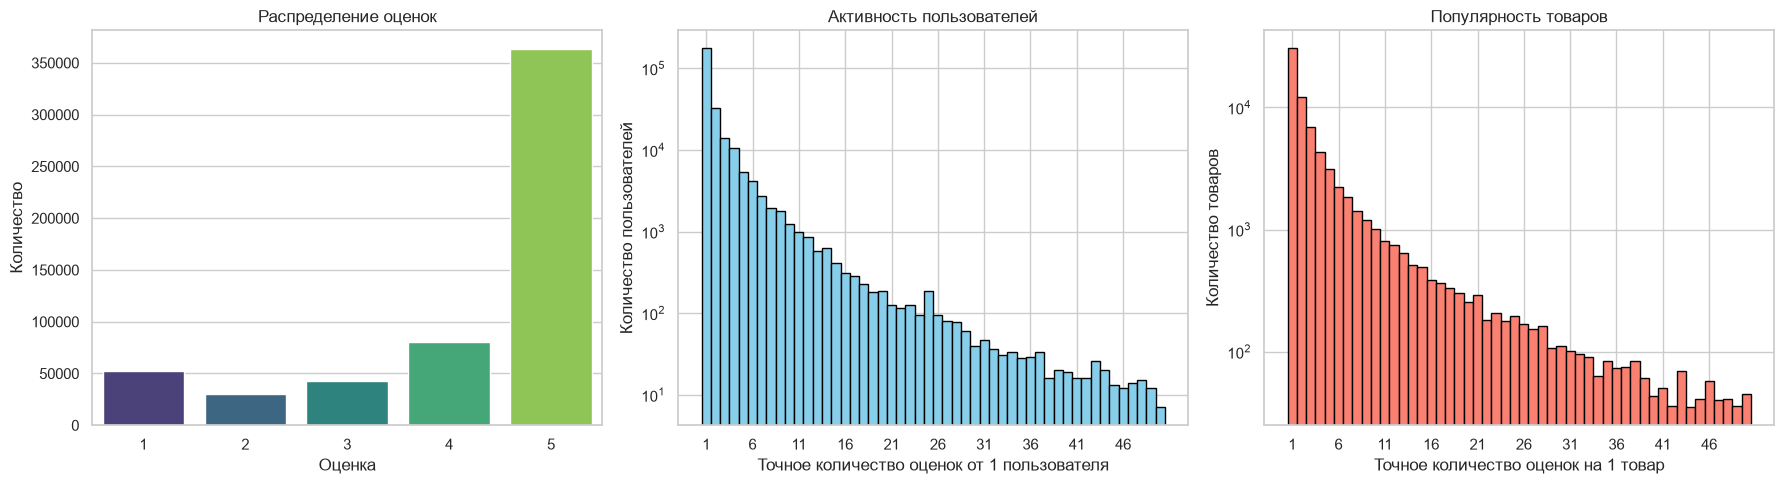

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

n_users = df["UserId"].nunique()
n_items = df["ProductId"].nunique()
n_ratings = len(df)

total_possible_interactions = n_users * n_items
sparsity = (1 - (n_ratings / total_possible_interactions)) * 100

user_activity = df.groupby("UserId")["Score"].count()
item_popularity = df.groupby("ProductId")["Score"].count()


print(f"Количество уникальных пользователей (N_users): {n_users:,}")
print(f"Количество уникальных объектов (N_items):     {n_items:,}")
print(f"Общее количество оценок (N_ratings):          {n_ratings:,}")
print(f"Разреженность матрицы взаимодействий:         {sparsity:.4f}%")
print(f"Среднее число оценок на пользователя:         {user_activity.mean():.2f}")
print(f"Медианное число оценок на пользователя:       {user_activity.median():.0f}")
print(f"Среднее число оценок на товар:                {item_popularity.mean():.2f}")
print(f"Медианное число оценок на товар:              {item_popularity.median():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(ax=axes[0], data=df, x="Score", palette="viridis")
axes[0].set_title("Распределение оценок")
axes[0].set_xlabel("Оценка")
axes[0].set_ylabel("Количество")


max_user_reviews = 50
filtered_user_act = user_activity[user_activity <= max_user_reviews]

axes[1].hist(
    filtered_user_act,
    bins=np.arange(1, max_user_reviews + 2) - 0.5,
    color="skyblue",
    edgecolor="black",
    log=True, 
)
axes[1].set_title(f"Активность пользователей")
axes[1].set_xlabel("Точное количество оценок от 1 пользователя")
axes[1].set_ylabel("Количество пользователей")
axes[1].set_xticks(range(1, max_user_reviews + 1, 5))

max_item_reviews = 50
filtered_item_pop = item_popularity[item_popularity <= max_item_reviews]

axes[2].hist(
    filtered_item_pop,
    bins=np.arange(1, max_item_reviews + 2) - 0.5,
    color="salmon",
    edgecolor="black",
    log=True,
)
axes[2].set_title(f"Популярность товаров")
axes[2].set_xlabel("Точное количество оценок на 1 товар")
axes[2].set_ylabel("Количество товаров")
axes[2].set_xticks(range(1, max_item_reviews + 1, 5))

plt.tight_layout()
plt.show()

Анализ датасета показал экстремально высокую степень разреженности матрицы взаимодействий (99.997%), что подтверждает необходимость использования методов понижения размерности (SVD / Matrix Factorization).Распределение активности пользователей имеет сильный скос: медианное значение оценок на пользователя равно 1 (среднее 2.22). Для устранения проблемы «холодного старта» и повышения качества обучения алгоритмов фильтрации на этапе предобработки рекомендуется применить фильтрацию неактивных пользователей (оставив пользователей более 3 или 5 взаиможействий)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split


content_col = "Text"

df_clean = df.dropna(subset=[content_col]).copy()


item_descriptions = (
    df_clean.groupby("ProductId")[content_col]
    .apply(lambda x: " ".join(str(v) for v in x if pd.notna(v)))
    .reset_index()
)


item_text_map = (
    df_clean.drop_duplicates(subset=["ProductId"])
    .set_index("ProductId")[content_col]
    .to_dict()
)


tfidf = TfidfVectorizer(max_features=10000, stop_words="english")
tfidf_matrix = tfidf.fit_transform(item_descriptions[content_col])

item_to_idx = {
    item_id: i for i, item_id in enumerate(item_descriptions["ProductId"])
}
idx_to_item = {
    i: item_id for i, item_id in enumerate(item_descriptions["ProductId"])
}



positive_df = df_clean[df_clean["Score"] >= 4].copy()
positive_df = positive_df[positive_df["ProductId"].isin(item_to_idx)]

train_df, test_df = train_test_split(
    positive_df, test_size=0.2, random_state=42
)


train_user_history = train_df.groupby("UserId")["ProductId"].apply(list)
test_user_items = test_df.groupby("UserId")["ProductId"].apply(set).to_dict()

K = 5
precisions, recalls = [], []

print("=" * 70)
print(f"Расчет метрик Precision@{K} и Recall@{K} на тестовой выборке...")

for user_id, actual_test_items in test_user_items.items():
    if user_id not in train_user_history:
        continue 

    train_items = train_user_history[user_id]
    user_indices = [
        item_to_idx[item_id] for item_id in train_items if item_id in item_to_idx
    ]
    if not user_indices:
        continue


    user_profile = tfidf_matrix[user_indices].mean(axis=0).A1
    scores = tfidf_matrix.dot(user_profile)
    scores[user_indices] = -1.0  # Исключаем просмотренные товары из Train

    
    top_k_indices = np.argpartition(scores, -K)[-K:]
    recommended_items = set(idx_to_item[i] for i in top_k_indices)

    hits = len(recommended_items & actual_test_items)

    precisions.append(hits / K)
    recalls.append(hits / len(actual_test_items))

mean_precision = np.mean(precisions) if precisions else 0.0
mean_recall = np.mean(recalls) if recalls else 0.0

print(f" Результаты валидации модели:")
print(f"   - Mean Precision@{K}: {mean_precision:.4f}")
print(f"   - Mean Recall@{K}:    {mean_recall:.4f}")


import os

full_user_history = positive_df.groupby("UserId")["ProductId"].apply(list)
unique_users = full_user_history.index.values
total_users = len(unique_users)

output_filename = "recommendations_text_top5.csv"

if os.path.exists(output_filename):
    os.remove(output_filename)

batch_size = 5000  

print(f"Размер пачки (batch_size): {batch_size}")

is_first_batch = True

for start_idx in range(0, total_users, batch_size):
    end_idx = min(start_idx + batch_size, total_users)
    batch_users = unique_users[start_idx:end_idx]

    batch_profiles = []
    batch_user_item_indices = []

    for user_id in batch_users:
        items = full_user_history[user_id]
        indices = [item_to_idx[item_id] for item_id in items]

        user_profile = tfidf_matrix[indices].mean(axis=0).A1
        batch_profiles.append(user_profile)
        batch_user_item_indices.append(indices)

    batch_profiles_matrix = np.vstack(batch_profiles)


    similarity_matrix = batch_profiles_matrix.dot(tfidf_matrix.T.toarray())

    batch_results = []

    for i, user_id in enumerate(batch_users):
        user_scores = similarity_matrix[i]
        user_indices = batch_user_item_indices[i]

        user_scores[user_indices] = -1.0

        top_5_indices = np.argpartition(user_scores, -5)[-5:]
        top_5_indices = top_5_indices[np.argsort(user_scores[top_5_indices])[
            ::-1
        ]]

        for rank, idx in enumerate(top_5_indices, 1):
            rec_item_id = idx_to_item[idx]
            score = user_scores[idx]
            full_text = str(
                item_text_map.get(rec_item_id, "Текст отзыва отсутствует")
            )

            if len(full_text) > 200:
                full_text = full_text[:197] + "..."

            batch_results.append(
                {
                    "UserId": user_id,
                    "Rank": rank,
                    "Recommended_ProductId": rec_item_id,
                    "Cosine_Score": round(float(score), 4),
                    "Text": full_text,
                }
            )

    batch_df = pd.DataFrame(batch_results)
    batch_df.to_csv(
        output_filename,
        mode="a",
        index=False,
        header=is_first_batch,
        encoding="utf-8",
    )
    is_first_batch = False

    print(f"Обработано пользователей: {end_idx:,} / {total_users:,}")


Расчет метрик Precision@5 и Recall@5 на тестовой выборке...
 Результаты валидации модели:
   - Mean Precision@5: 0.0199
   - Mean Recall@5:    0.0805
Запуск пакетной генерации Top-5 рекомендаций для 207,050 пользователей...
Размер пачки (batch_size): 5000
Обработано пользователей: 5,000 / 207,050
Обработано пользователей: 10,000 / 207,050
Обработано пользователей: 15,000 / 207,050
Обработано пользователей: 20,000 / 207,050
Обработано пользователей: 25,000 / 207,050
Обработано пользователей: 30,000 / 207,050
Обработано пользователей: 35,000 / 207,050
Обработано пользователей: 40,000 / 207,050
Обработано пользователей: 45,000 / 207,050
Обработано пользователей: 50,000 / 207,050
Обработано пользователей: 55,000 / 207,050
Обработано пользователей: 60,000 / 207,050
Обработано пользователей: 65,000 / 207,050
Обработано пользователей: 70,000 / 207,050
Обработано пользователей: 75,000 / 207,050
Обработано пользователей: 80,000 / 207,050
Обработано пользователей: 85,000 / 207,050
Обработано пол